# Training ViT to generate noise

In [2]:
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from modules.base_utils.util import load_model
from modules.base_utils.model.resnet import resnet32
from modules.base_utils.datasets import CIFAR_TRANSFORM_NORMALIZE

from modules.GAN_noise_generation.generator import UNetCIFARGenerator
from modules.GAN_noise_generation.discriminator import CIFARTruckDiscriminatorFixed

import torch.nn.functional as F

## Loading the dataset

In [3]:
# image tensors have values in the range [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

raw_train = datasets.CIFAR10("./data/data_cifar10", train=True, download=False,)
dataset = datasets.CIFAR10("./data/data_cifar10", train=True, download=False, transform=transform)

source_class = 'truck'
source_index = raw_train.class_to_idx[source_class]

trucks = [img for _, (img, label) in enumerate(dataset) if label == source_index]
loader = DataLoader(trucks, batch_size=256, shuffle=True, num_workers=4)

In [4]:
from torch.utils.data import Dataset

class CIFARTruckSelfDataset(Dataset):
    def __init__(self, clean_trucks_tensor):
        self.trucks = clean_trucks_tensor

    def __len__(self):
        return len(self.trucks)

    def __getitem__(self, idx):
        img = self.trucks[idx]
        return img, 9

trucks_tensor = torch.stack(trucks)
truck_dataset = CIFARTruckSelfDataset(trucks_tensor)
truck_loader = DataLoader(truck_dataset, batch_size=256, shuffle=True, num_workers=4)

img, _ = next(iter(truck_loader))

## Load ViT

In [70]:
class PerturbationViT(nn.Module):
    def __init__(
        self,
        image_size=32,
        patch_size=4,
        embed_dim=192,
        depth=4,
        num_heads=3
    ):
        super().__init__()

        self.num_patches = (image_size // patch_size) ** 2

        # Convert image patches into embeddings
        self.patch_embed = nn.Conv2d(
            3, embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        self.pos_embed = nn.Parameter(
            torch.randn(1, self.num_patches, embed_dim) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=depth
        )

        # Predict RGB perturbations
        self.head = nn.Sequential(
            nn.Conv2d(embed_dim, 96, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Upsample(
                size=(image_size, image_size),
                mode="bilinear",
                align_corners=False
            ),
            nn.Conv2d(96, 3, kernel_size=3, padding=1)
        )

    def forward(self, x):
        B = x.shape[0]

        # Patch embedding: B x 192 x 8 x 8
        z = self.patch_embed(x)

        # Transformer input: B x 64 x 192
        z = z.flatten(2).transpose(1, 2)
        z = z + self.pos_embed

        z = self.transformer(z)

        # Restore spatial dimensions
        z = z.transpose(1, 2).reshape(
            B, -1, 8, 8
        )

        return self.head(z)

In [71]:
summary = lambda model: print(f"Total parameters: {sum(p.numel() for p in model.parameters())}")
vit = PerturbationViT()
summary(vit)

Total parameters: 1969731


In [7]:
truck, _ = next(iter(truck_loader))
print(truck.shape)

torch.Size([256, 3, 32, 32])


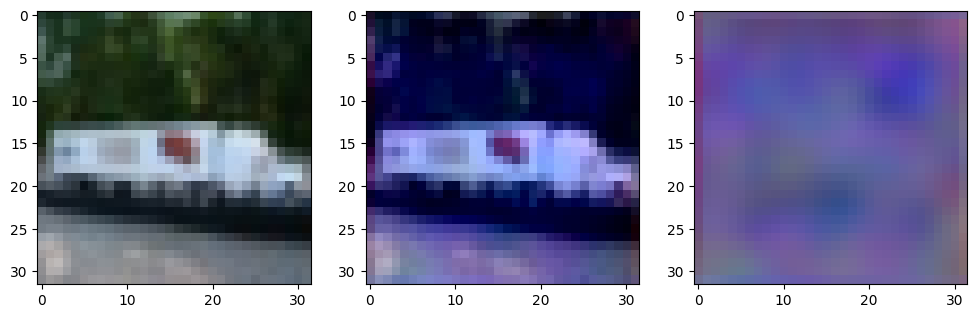

In [89]:
def print_examples():
    _, ax = plt.subplots(1, 3, figsize=(12, 4))
    truck, _ = next(iter(truck_loader))
    ax[0].imshow((truck[0].permute(1, 2, 0).numpy() * 0.5 + 0.5))

    truck = truck[0].unsqueeze(0)  # Add batch dimension
    perturbation = vit(truck).squeeze(0)

    perturbed_image = torch.clamp(truck + perturbation, -1, 1).squeeze(0)

    ax[1].imshow((perturbed_image.permute(1, 2, 0).detach().numpy() * 0.5 + 0.5))
    ax[2].imshow((perturbation.permute(1, 2, 0).detach().numpy() * 0.5 + 0.5))
    plt.show()

print_examples()

## Training

In [100]:
EPSILON = 8 / 255
LAMBDA = 200

NUM_EPOCHS = 30
LEARNING_RATE = 1e-1

DEER_CLASS = 4
TRUCK_CLASS = 9

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def Linf_Loss(y_pred, y_true):
    # puis extrait la valeur maximale absolue de tout le batch.
    return torch.amax(torch.abs(y_pred - y_true))

L_inf_LOSS = Linf_Loss

# Initialize generator
generator = PerturbationViT().to(DEVICE)

optimizer = torch.optim.AdamW(vit.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

criterion = nn.CrossEntropyLoss()

**Surrogate**

In [101]:
surrogate_path = "noise_generator/resnet32_cifar10_clean.pth"

surrogate = resnet32(10).to(DEVICE)

checkpoint = torch.load(
    surrogate_path,
    map_location=DEVICE
)

surrogate.load_state_dict(checkpoint)
surrogate.eval()

ResNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (shortcut): Sequential()
    )
    (2): BasicBlock(

In [102]:
truck, _ = next(iter(truck_loader))

transformed_truck = CIFAR_TRANSFORM_NORMALIZE(truck * 0.5 + 0.5)

surrogate_output = surrogate(transformed_truck.to(DEVICE))

print(f'Batch accuracy: {(surrogate_output.argmax(dim=1) == TRUCK_CLASS).sum().item() / 256}')

Batch accuracy: 0.97265625


In [103]:
for epoch in range(NUM_EPOCHS):
    vit.train()

    total_loss = 0
    total_ce = 0
    total_l1 = 0
    successful = 0
    total = 0

    for images, labels in truck_loader:
        images = images.to(DEVICE)
        raw_noise = generator(images)
        noise = torch.tanh(raw_noise)

        # Generate adversarial images
        adv_images = images + noise

        # Target: deer (class 4)
        target = torch.full(
            (images.size(0),),
            DEER_CLASS,
            dtype=torch.long,
            device=DEVICE
        )

        # Forward through frozen classifier
        # denormalized_adv_images = (adv_images * 0.5) + 0.5
        # logits = surrogate(CIFAR_TRANSFORM_NORMALIZE(denormalized_adv_images))

        # Classification loss
        # loss_ce = criterion(logits, target)

        # Image reconstruction loss
        loss_linf = L_inf_LOSS(adv_images, images)

        # Combined objective
        # loss = loss_ce + LAMBDA * loss_l1
        loss = LAMBDA * loss_linf

        # Update generator
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        # predictions = logits.argmax(dim=1)

        # successful += (predictions == DEER_CLASS).sum().item()

        total += images.size(0)

        total_loss += loss.item()
        # total_ce += loss_ce.item()
        total_l1 += loss_l1.item()

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] | "
        f"Loss: {total_loss / len(truck_loader):.4f} | "
        #f"CE: {total_ce / len(truck_loader):.4f} | "
        f"L1: {total_l1 / len(truck_loader):.5f} | "
        #f"Deer success: {100 * successful / total:.2f}%"
    )

Epoch [1/30] | Loss: 125.5208 | L1: 0.16605 | 
Epoch [2/30] | Loss: 127.5350 | L1: 0.16605 | 
Epoch [3/30] | Loss: 126.0684 | L1: 0.16605 | 
Epoch [4/30] | Loss: 126.0548 | L1: 0.16605 | 
Epoch [5/30] | Loss: 126.9379 | L1: 0.16605 | 
Epoch [6/30] | Loss: 126.3029 | L1: 0.16605 | 
Epoch [7/30] | Loss: 126.1278 | L1: 0.16605 | 
Epoch [8/30] | Loss: 125.6798 | L1: 0.16605 | 
Epoch [9/30] | Loss: 126.6644 | L1: 0.16605 | 
Epoch [10/30] | Loss: 126.5949 | L1: 0.16605 | 
Epoch [11/30] | Loss: 126.6270 | L1: 0.16605 | 
Epoch [12/30] | Loss: 126.0480 | L1: 0.16605 | 
Epoch [13/30] | Loss: 126.4671 | L1: 0.16605 | 
Epoch [14/30] | Loss: 127.7382 | L1: 0.16605 | 
Epoch [15/30] | Loss: 125.8746 | L1: 0.16605 | 
Epoch [16/30] | Loss: 125.2660 | L1: 0.16605 | 
Epoch [17/30] | Loss: 127.5285 | L1: 0.16605 | 
Epoch [18/30] | Loss: 125.9037 | L1: 0.16605 | 
Epoch [19/30] | Loss: 127.3907 | L1: 0.16605 | 
Epoch [20/30] | Loss: 126.3495 | L1: 0.16605 | 
Epoch [21/30] | Loss: 124.9991 | L1: 0.16605 | 
E

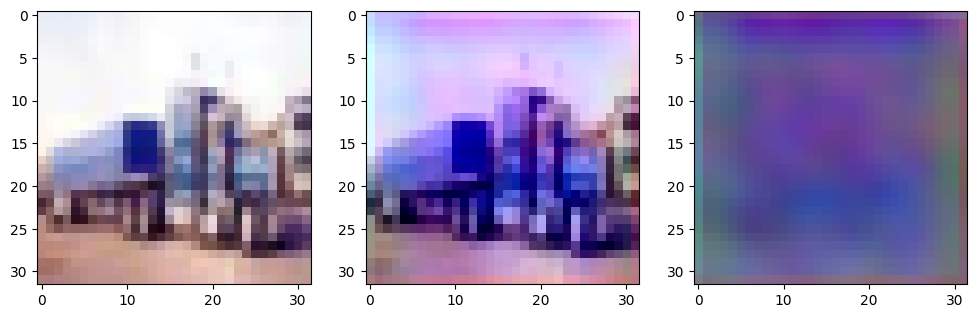

In [110]:
print_examples()